In [5]:
#lHUCAS SANDOVAL
#21704400-6

In [6]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(seed=1511)   # semilla para reproducibilidad
N = 100

catalogo = pd.DataFrame({
    "ID": [f"Estrella_{i:03d}" for i in range(1, N + 1)],
    "R_estelar": rng.uniform(0.5, 5, N),        # Radio estelar
    "d_pc": rng.uniform(50, 500, N),         # Distancia (pc)
    "Temp_k": rng.uniform(3000, 10000, N),   # Temperatura efectiva (K)
})

print(catalogo.head(10))
print(catalogo.describe())

             ID  R_estelar        d_pc       Temp_k
0  Estrella_001   1.350598   88.688969  3198.473515
1  Estrella_002   0.904511  176.565556  9709.382482
2  Estrella_003   3.059657  457.580124  4963.011185
3  Estrella_004   3.461708   63.384279  7844.952641
4  Estrella_005   2.073642  285.667503  6494.194630
5  Estrella_006   4.472692  279.355609  9472.209454
6  Estrella_007   4.858169  272.922599  3582.050179
7  Estrella_008   1.647741   95.502896  7662.420095
8  Estrella_009   2.291260  111.510452  4831.101974
9  Estrella_010   4.571070  141.025534  5416.851993
        R_estelar        d_pc       Temp_k
count  100.000000  100.000000   100.000000
mean     2.800245  268.506211  6683.199474
std      1.305479  126.748446  2019.258460
min      0.587779   63.384279  3047.120647
25%      1.542968  156.273763  5044.258398
50%      2.976161  269.122726  6698.962463
75%      3.830783  373.983751  8465.415929
max      4.980320  495.829147  9964.210486


In [7]:
sigma_SB = 5.670374419e-8   # Constante de Stefan-Boltzmann W m^-2 K^-4
R_sol    = 6.957e8          # Radio solar m
L_sol    = 3.828e26         # Luminosidad solar W
pc_m       = 3.0857e16        # Parsec a metros

#Conversión de unidades para las fórmulas

R_m = catalogo["R_estelar"].to_numpy() * R_sol       # R en metros
T   = catalogo["Temp_k"].to_numpy()

#Calcular la luminosidad mediante la ley de Stefan-Boltzmann (en Watts)

L_W = 4 * np.pi * R_m**2 * sigma_SB * T**4        # en watts
L_Lsol = L_W / L_sol                              # en L_sol

#Calculo de flujo observado en W m^-2

d_m = catalogo["d_pc"].to_numpy() * pc_m    # d en metros
F = L_W / (4 * np.pi * d_m**2)                   # W m^-2

#Agregamos a nuestro DataFrame

catalogo["Lum_sol"] = L_sol
catalogo["Flujo_Wm2"] = F

print(catalogo.head(10))

#Estrellas con mayor y menos luminosidad y flujo

idx_Lmax = catalogo["Lum_sol"].idxmax()
idx_Lmin = catalogo["Lum_sol"].idxmin()
idx_Fmax = catalogo["Flujo_Wm2"].idxmax()
idx_Fmin = catalogo["Flujo_Wm2"].idxmin()

print("Mayor luminosidad:\n", catalogo.loc[idx_Lmax], "\n")
print("Menor luminosidad:\n", catalogo.loc[idx_Lmin], "\n")
print("Mayor flujo:\n", catalogo.loc[idx_Fmax], "\n")
print("Menor flujo:\n", catalogo.loc[idx_Fmin])

             ID  R_estelar        d_pc       Temp_k       Lum_sol  \
0  Estrella_001   1.350598   88.688969  3198.473515  3.828000e+26   
1  Estrella_002   0.904511  176.565556  9709.382482  3.828000e+26   
2  Estrella_003   3.059657  457.580124  4963.011185  3.828000e+26   
3  Estrella_004   3.461708   63.384279  7844.952641  3.828000e+26   
4  Estrella_005   2.073642  285.667503  6494.194630  3.828000e+26   
5  Estrella_006   4.472692  279.355609  9472.209454  3.828000e+26   
6  Estrella_007   4.858169  272.922599  3582.050179  3.828000e+26   
7  Estrella_008   1.647741   95.502896  7662.420095  3.828000e+26   
8  Estrella_009   2.291260  111.510452  4831.101974  3.828000e+26   
9  Estrella_010   4.571070  141.025534  5416.851993  3.828000e+26   

      Flujo_Wm2  
0  6.995718e-13  
1  6.722502e-12  
2  7.818810e-13  
3  3.256322e-10  
4  2.701440e-12  
5  5.948079e-11  
6  1.503631e-12  
7  2.957721e-11  
8  6.629044e-12  
9  2.607212e-11  
Mayor luminosidad:
 ID                    

In [8]:
F_lim = 2e-10   # W m^-2

#Columna de clasificación

catalogo["Clasificacion"] = np.where(
    catalogo["Flujo_Wm2"] >= F_lim, "Detectada", "No detectada"
)

#Número de estrellas por categoría

conteo = (catalogo["Clasificacion"]
          .value_counts()
          .reindex(["Detectada", "No detectada"], fill_value=0))
print("Estrellas por categoría:\n", conteo, "\n")

#Porcentaje de estrellas detectadas

pct_det = (catalogo["Clasificacion"] == "Detectada").mean() * 100
print(f"Porcentaje de estrellas detectadas: {pct_det:.1f} %\n")

#Promedios por categoría

promedios = (catalogo
             .groupby("Clasificacion")[["Flujo_Wm2", "d_pc", "Temp_k"]]
             .mean()
             .rename(columns={"Flujo_Wm2": "Flujo medio (W m^-2)",
                              "d_pc": "Distancia media (pc)",
                              "Temp_k": "Teff media (K)"}))
print(promedios)

Estrellas por categoría:
 Clasificacion
Detectada        3
No detectada    97
Name: count, dtype: int64 

Porcentaje de estrellas detectadas: 3.0 %

               Flujo medio (W m^-2)  Distancia media (pc)  Teff media (K)
Clasificacion                                                            
Detectada              4.225408e-10             71.033173     8416.874623
No detectada           1.542960e-11            274.613624     6629.580655


<ipython-input-9-ab5546a4932a>:19: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  fig.tight_layout()
<ipython-input-9-ab5546a4932a>:19: MatplotlibDeprecationWarning: The height parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(height) instead.
  fig.tight_layout()
<ipython-input-9-ab5546a4932a>:19: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  fig.tight_layout()
<ipython-input-9-ab5546a4932a>:19: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  fig.tight_layout()
<ipython-input-9-ab5546a4932a>:67: MatplotlibDeprecationWarning: The width parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(width) instead.
  fig.tight_layout()
<ipy

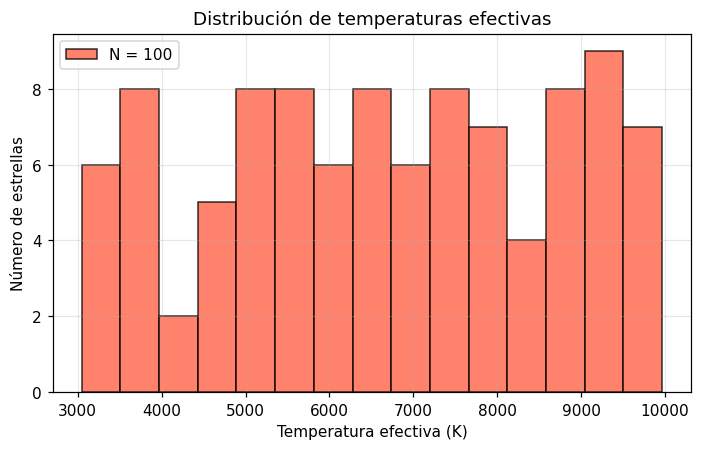

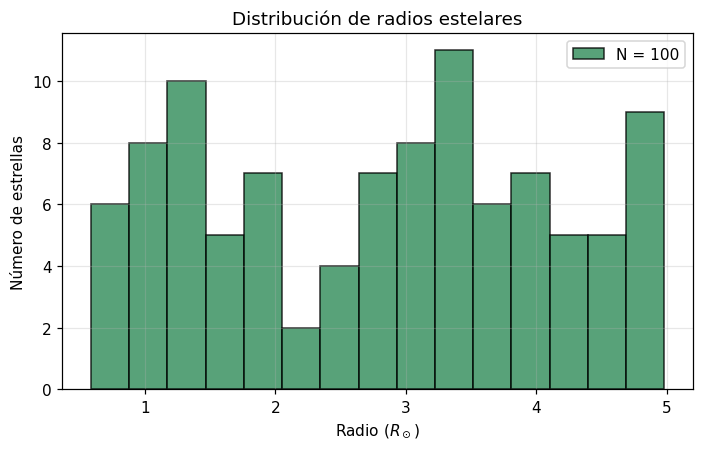

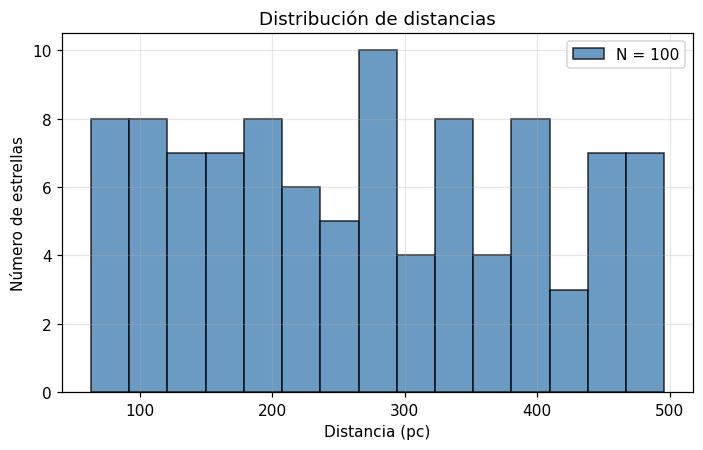

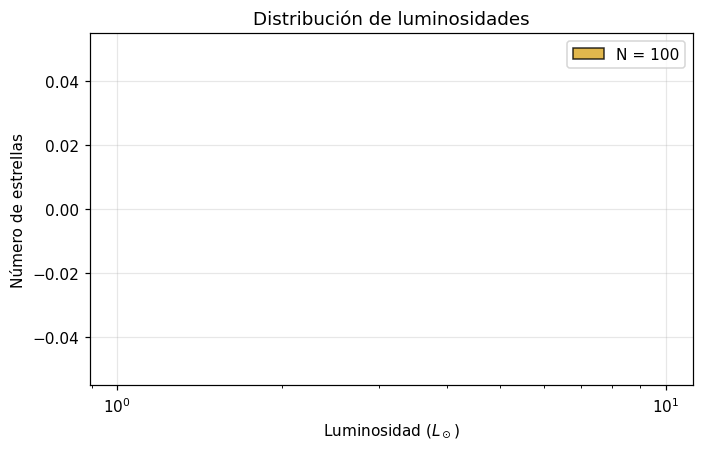

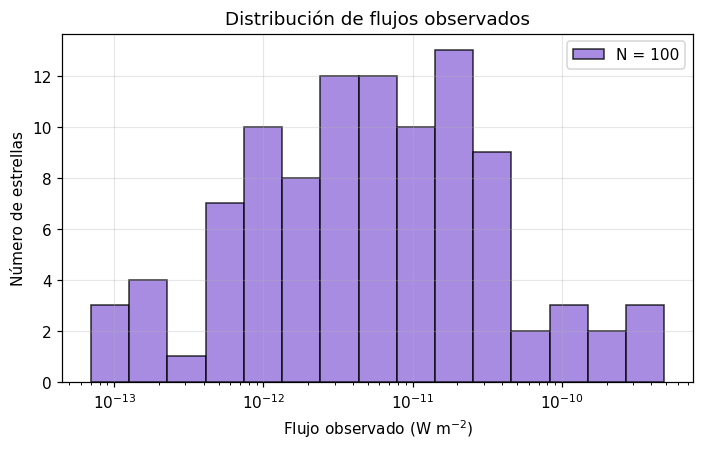

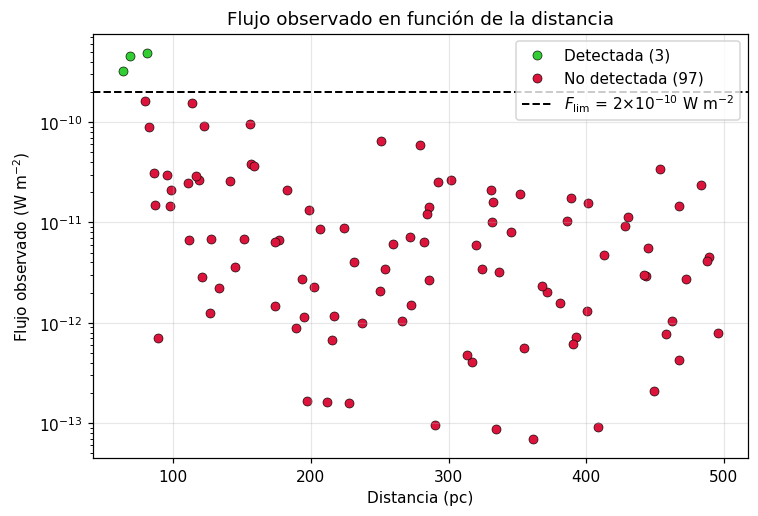

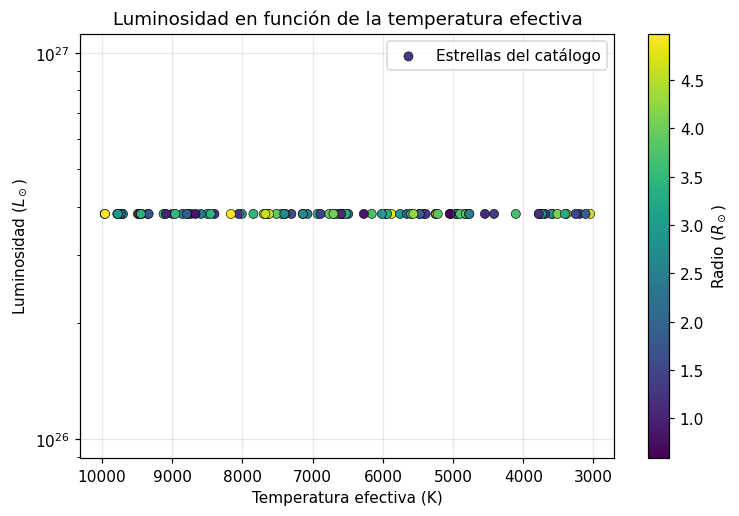

In [9]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def histograma(datos, titulo, xlabel, color, log=False, bins=15):
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    if log:
        bordes = np.logspace(np.log10(datos.min()), np.log10(datos.max()), bins + 1)
        ax.hist(datos, bins=bordes, color=color, edgecolor="black", alpha=0.8,
                label=f"N = {len(datos)}")
        ax.set_xscale("log")
    else:
        ax.hist(datos, bins=bins, color=color, edgecolor="black", alpha=0.8,
                label=f"N = {len(datos)}")
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Número de estrellas")
    ax.legend()
    fig.tight_layout()
    return fig

#Temperatura efectiva

histograma(catalogo["Temp_k"],
           "Distribución de temperaturas efectivas",
           "Temperatura efectiva (K)", "tomato")

#Radio estelar
histograma(catalogo["R_estelar"],
           "Distribución de radios estelares",
           r"Radio ($R_\odot$)", "seagreen")

#Distancia

histograma(catalogo["d_pc"],
           "Distribución de distancias",
           "Distancia (pc)", "steelblue")

#Luminosidad (bins logarítmicos por la gran dispersión)

histograma(catalogo["Lum_sol"],
           "Distribución de luminosidades",
           r"Luminosidad ($L_\odot$)", "goldenrod", log=True)

# (e) Flujo (bins logarítmicos)

histograma(catalogo["Flujo_Wm2"],
           "Distribución de flujos observados",
           r"Flujo observado (W m$^{-2}$)", "mediumpurple", log=True)

# (f) Flujo vs distancia

fig, ax = plt.subplots(figsize=(7, 4.8))
estilos = {"Detectada": "limegreen", "No detectada": "crimson"}
for clase, color in estilos.items():
    sub = catalogo[catalogo["Clasificacion"] == clase]
    ax.scatter(sub["d_pc"], sub["Flujo_Wm2"], c=color, s=35,
               edgecolor="black", linewidth=0.4,
               label=f"{clase} ({len(sub)})")
ax.axhline(F_lim, color="black", linestyle="--", linewidth=1.3,
           label=r"$F_{\rm lim}$ = 2×10$^{-10}$ W m$^{-2}$")
ax.set_yscale("log")
ax.set_title("Flujo observado en función de la distancia")
ax.set_xlabel("Distancia (pc)")
ax.set_ylabel(r"Flujo observado (W m$^{-2}$)")
ax.legend()
fig.tight_layout()

#Luminosidad vs Teff (eje de temperatura invertido)

fig, ax = plt.subplots(figsize=(7, 4.8))
sc = ax.scatter(catalogo["Temp_k"], catalogo["Lum_sol"],
                c=catalogo["R_estelar"], cmap="viridis", s=35,
                edgecolor="black", linewidth=0.4, label="Estrellas del catálogo")
ax.set_yscale("log")
ax.invert_xaxis()   # temperatura de mayor a menor
ax.set_title("Luminosidad en función de la temperatura efectiva")
ax.set_xlabel("Temperatura efectiva (K)")
ax.set_ylabel(r"Luminosidad ($L_\odot$)")
cb = fig.colorbar(sc, ax=ax)
cb.set_label(r"Radio ($R_\odot$)")
ax.legend()
fig.tight_layout()

plt.show()